# Validación de BaseUnificada antes del análisis

Complementa el notebook 02, que conserva el proceso de transformación L00 a L14.
Lee la última entrega verificada. No imputa, modifica ni elimina sus registros.
Examina cobertura por grupo, similitud con Oracle y denominadores de indicadores.
El escenario de consolidación es una prueba de sensibilidad, no una base depurada nueva.

In [1]:
from pathlib import Path
import hashlib
import json
from decimal import Decimal
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
summary_path = ROOT / 'reports/limpieza/ultima_entrega.json'
summary_bytes = summary_path.read_bytes()
summary = json.loads(summary_bytes)
notebook_path = ROOT / 'notebooks/03_validacion_previa_analisis.ipynb'
notebook_code = '\n'.join(c.source for c in nbformat.read(notebook_path, as_version=4).cells
                          if c.cell_type == 'code')
notebook_code_sha = hashlib.sha256(notebook_code.encode()).hexdigest()
SOURCE = ROOT / summary['datos_salida'] / 'entregable'
OUT = ROOT / 'reports/validacion_analisis' / summary['id_ejecucion']
OUT.mkdir(parents=True, exist_ok=True)

def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

delivery_paths = {ROOT / p: digest for p, digest in summary['archivos_entregables'].items()}
assert all(sha(p) == digest for p, digest in delivery_paths.items())
source_hashes = {p.name: sha(p) for p in SOURCE.glob('*.csv')}

def read(name):
    return pd.read_csv(SOURCE / name, dtype=str, keep_default_na=False, encoding='utf-8-sig')

base = read('BaseUnificada_Entregable.csv').set_index('registro_id', drop=False)
original = base.copy(deep=True)
origin = read('Origen_Registros.csv').set_index('registro_id')
quality = read('Control_Calidad.csv').set_index('registro_id')
pairs = read('Coincidencias_Oracle.csv')
assert len(base) == 5500 and len(base.columns) == 18 and base.index.is_unique
assert base.index.equals(origin.index) and base.index.equals(quality.index)
analysis = base.join(origin[['fuente_origen']])
N = len(base)
def save(frame, name):
    frame.to_csv(OUT / name, index=False, encoding='utf-8-sig', lineterminator='\n')
display(pd.DataFrame([{'Registros': N, 'Columnas': len(base.columns),
                      'Entrada': summary['id_ejecucion']}]))

,Registros,Columnas,Entrada
0,5500,18,entrega_v1_6b14cc9ccf_716b06df_d0dca438_5cdda3c2


## 1. Cobertura y concentración de ausencias

Se cuenta cada columna vacía y se cruza con programa, modalidad, canal, estado,
periodo y fuente. El porcentaje usa todos los registros de cada grupo.
Sin información es una etiqueta de presentación, no un valor imputado.
Las diferencias en puntos porcentuales son descriptivas. No prueban que las ausencias
sean aleatorias o que exista una causa. La fecha de matrícula se interpreta por estado.

,columna,registros,informados,ausentes,porcentaje_ausente
1,aspirante_id,5500,5410,90,1.6364
3,programa,5500,5474,26,0.4727
7,puntaje_admision,5500,5254,246,4.4727
9,valor_matricula_cop,5500,4580,920,16.7273
12,fecha_matricula,5500,1179,4321,78.5636
13,correo,5500,5370,130,2.3636
15,facultad,5500,5474,26,0.4727
16,duracion_semestres,5500,5474,26,0.4727
17,nivel_formacion,5500,5474,26,0.4727


,dimension,categoria,columna,registros_grupo,ausentes,informados,porcentaje_ausente,diferencia_pp_frente_total
3,programa,Sin información,valor_matricula_cop,26,5,21,19.2308,2.5035
93,canal_captacion,Referido,valor_matricula_cop,915,166,749,18.1421,1.4148
105,estado_proceso,Admitido,valor_matricula_cop,1822,321,1501,17.6180,0.8907
51,modalidad,Híbrida,valor_matricula_cop,1125,197,928,17.5111,0.7838
141,periodo_academico,20252,valor_matricula_cop,1071,187,884,17.4603,0.7330
165,fuente_origen,Principal,valor_matricula_cop,5000,839,4161,16.7800,0.0527
2,programa,Sin información,puntaje_admision,26,2,24,7.6923,3.2196
110,estado_proceso,Documentación pendiente,puntaje_admision,638,39,599,6.1129,1.6401
92,canal_captacion,Referido,puntaje_admision,915,53,862,5.7923,1.3196
62,modalidad,Virtual,puntaje_admision,2183,107,2076,4.9015,0.4288


,dimension,categoria,columna,registros_grupo,ausentes,informados,porcentaje_ausente,diferencia_pp_frente_total
106,estado_proceso,Admitido,fecha_matricula,1822,1822,0,100.0,21.4364
112,estado_proceso,Documentación pendiente,fecha_matricula,638,638,0,100.0,21.4364
118,estado_proceso,Inscrito,fecha_matricula,630,630,0,100.0,21.4364
124,estado_proceso,Matriculado,fecha_matricula,1179,0,1179,0.0,-78.5636
130,estado_proceso,No admitido,fecha_matricula,617,617,0,100.0,21.4364
136,estado_proceso,Retirado,fecha_matricula,614,614,0,100.0,21.4364


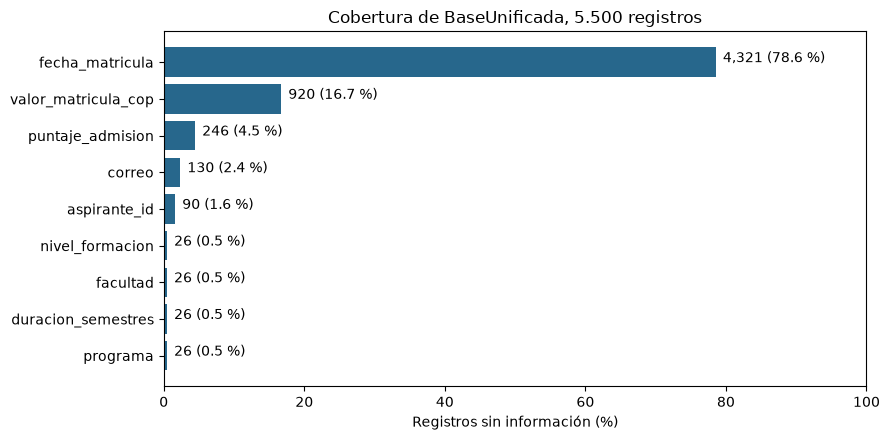

In [2]:
coverage = pd.DataFrame([{'columna': c, 'registros': N,
    'informados': int(base[c].ne('').sum()), 'ausentes': int(base[c].eq('').sum()),
    'porcentaje_ausente': round(base[c].eq('').mean() * 100, 4)} for c in base.columns])
save(coverage, 'cobertura_columnas.csv')
targets = ['programa', 'aspirante_id', 'puntaje_admision', 'valor_matricula_cop',
           'fecha_matricula', 'correo']
dimensions = ['programa', 'modalidad', 'canal_captacion', 'estado_proceso',
              'periodo_academico', 'fuente_origen']
group_rows = []
for dimension in dimensions:
    for category, group in analysis.groupby(dimension, dropna=False, sort=True):
        for c in targets:
            count = int(group[c].eq('').sum())
            group_rows.append({'dimension': dimension, 'categoria': category or 'Sin información',
                'columna': c, 'registros_grupo': len(group), 'ausentes': count,
                'informados': len(group) - count,
                'porcentaje_ausente': round(count / len(group) * 100, 4),
                'diferencia_pp_frente_total': round((count / len(group) - base[c].eq('').mean()) * 100, 4)})
by_group = pd.DataFrame(group_rows)
save(by_group, 'ausencias_por_grupo.csv')
# Se evita interpretar la ausencia de la misma variable usada para agrupar.
comparison = by_group.loc[(by_group.dimension != by_group.columna) &
    by_group.columna.isin(['puntaje_admision', 'valor_matricula_cop'])].copy()
extremes = comparison.sort_values('porcentaje_ausente', ascending=False).groupby(
    ['dimension', 'columna'], sort=False).head(1)
save(extremes, 'mayor_ausencia_por_dimension.csv')
display(coverage.loc[coverage.ausentes.gt(0)])
display(extremes)
dates_by_state = by_group.loc[(by_group.dimension == 'estado_proceso') &
                             (by_group.columna == 'fecha_matricula')]
display(dates_by_state)
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = coverage.loc[coverage.ausentes.gt(0)].sort_values('porcentaje_ausente')
ax.barh(plot_data.columna, plot_data.porcentaje_ausente, color='#27678c')
ax.set(xlabel='Registros sin información (%)', title='Cobertura de BaseUnificada, 5.500 registros')
ax.set_xlim(0, 100)
for i, row in enumerate(plot_data.itertuples()):
    ax.text(row.porcentaje_ausente + 1, i, f'{row.ausentes:,} ({row.porcentaje_ausente:.1f} %)')
fig.tight_layout()
fig.savefig(OUT / 'ausencias_por_columna.png', dpi=180)
display(fig)
plt.close(fig)

## 2. Comprobación de candidatos Oracle sobre los valores finales

Se reevalúan los 500 pares ya identificados, sin buscar equivalencias por código.
La llave exploratoria exige correo, fecha de solicitud, programa, modalidad y periodo
informados e iguales. Además se comprueban contradicciones entre los demás atributos
informados, salvo los dos identificadores propios de cada sistema.
Compartir un vacío no se cuenta como atributo informado coincidente.
La compatibilidad de un par no demuestra que represente una sola solicitud.

In [3]:
keys = ['correo', 'fecha_solicitud', 'programa', 'modalidad', 'periodo_academico']
numeric = ['puntaje_admision', 'valor_matricula_cop', 'duracion_semestres']
comparable = [c for c in base.columns if c not in ['registro_id', 'aspirante_id']]
def equivalent(a, b, column):
    return Decimal(a) == Decimal(b) if column in numeric else a == b

checks = []
for pair in pairs.to_dict('records'):
    assert pair['candidatos_por_11_atributos'] == '1'
    oid, pid = pair['registro_id_oracle'], pair['registros_principales_candidatos']
    o, p = base.loc[oid], base.loc[pid]
    assert origin.loc[oid, 'fuente_origen'] == 'Oracle'
    assert origin.loc[pid, 'fuente_origen'] == 'Principal'
    equal = [c for c in comparable if o[c] != '' and p[c] != '' and equivalent(o[c], p[c], c)]
    conflicts = [c for c in comparable if o[c] != '' and p[c] != '' and not equivalent(o[c], p[c], c)]
    missing_both = [c for c in comparable if o[c] == p[c] == '']
    key_match = all(o[c] != '' and p[c] != '' and equivalent(o[c], p[c], c) for c in keys)
    checks.append({'registro_id_oracle': oid, 'registro_id_principal': pid,
        'candidato_previo_13_atributos': pair['candidatos_por_13_atributos'] == '1',
        'llave_exploratoria_informada_igual': key_match,
        'atributos_informados_iguales': len(equal), 'contradicciones_informadas': len(conflicts),
        'columnas_con_contradiccion': ', '.join(conflicts),
        'columnas_vacias_en_ambos': ', '.join(missing_both),
        'matricula_informada_en_ambos': o['fecha_matricula'] != '' and p['fecha_matricula'] != '',
        'compatible_para_escenario': key_match and not conflicts})
pair_review = pd.DataFrame(checks)
assert len(pair_review) == 500 and pair_review.registro_id_oracle.is_unique
assert pair_review.registro_id_principal.is_unique
save(pair_review, 'revision_pares_oracle.csv')
strict = pair_review.loc[pair_review.candidato_previo_13_atributos]
scenario_pairs = pair_review.loc[pair_review.compatible_para_escenario]
display(pd.DataFrame([{'Pares revisados': len(pair_review),
    'Candidatos previos de 13 atributos': len(strict),
    'De esos, matrícula informada en ambos': int(strict.matricula_informada_en_ambos.sum()),
    'Compatibles con la regla del escenario': len(scenario_pairs)}]))
display(pair_review.columnas_con_contradiccion.value_counts().rename('Pares').to_frame())

,Pares revisados,Candidatos previos de 13 atributos,"De esos, matrícula informada en ambos",Compatibles con la regla del escenario
0,500,49,0,49


,Pares
columnas_con_contradiccion,
fecha_solicitud,351
"fecha_solicitud, fecha_matricula",89
,49
fecha_matricula,11


## 3. Sensibilidad de las distribuciones

La referencia conserva los 5.500 registros. Se compara con una vista hipotética que
cuenta una vez cada par compatible y conserva la fila principal. No se reemplaza
la entrega ni se confirma identidad. La vista principal de 5.000 registros se incluye
como comparación de cobertura de fuentes, no como propuesta de descartar Oracle.
Los porcentajes de cada escenario usan su propio total y mantienen los programas
sin información como categoría visible. Se reportan diferencias en puntos porcentuales.

In [4]:
scenario_ids = set(scenario_pairs.registro_id_oracle)
scenarios = {'Integrada': analysis,
    'Pares compatibles contados una vez, hipotético': analysis.drop(index=list(scenario_ids)),
    'Solo principal, comparación de fuente': analysis.loc[analysis.fuente_origen.eq('Principal')]}
sensitivity_rows = []
for dimension in ['programa', 'modalidad', 'canal_captacion', 'estado_proceso', 'ciudad_residencia']:
    categories = sorted(analysis[dimension].unique())
    ref = analysis[dimension].value_counts()
    for name, frame in scenarios.items():
        counts = frame[dimension].value_counts()
        for category in categories:
            pct = counts.get(category, 0) / len(frame) * 100
            sensitivity_rows.append({'dimension': dimension, 'categoria': category or 'Sin información',
                'escenario': name, 'registros': int(counts.get(category, 0)),
                'denominador': len(frame), 'porcentaje': round(pct, 6),
                'diferencia_pp_frente_integrada': round(pct - ref.get(category, 0) / N * 100, 6)})
sensitivity = pd.DataFrame(sensitivity_rows)
save(sensitivity, 'sensibilidad_distribuciones.csv')
max_changes = sensitivity.assign(cambio_absoluto_pp=lambda d: d.diferencia_pp_frente_integrada.abs()).groupby(
    ['escenario', 'dimension'], as_index=False).cambio_absoluto_pp.max()
save(max_changes, 'sensibilidad_cambio_maximo.csv')
display(max_changes)

,escenario,dimension,cambio_absoluto_pp
0,Integrada,canal_captacion,0.000000
1,Integrada,ciudad_residencia,0.000000
2,Integrada,estado_proceso,0.000000
3,Integrada,modalidad,0.000000
4,Integrada,programa,0.000000
5,"Pares compatibles contados una vez, hipotético",canal_captacion,0.103364
6,"Pares compatibles contados una vez, hipotético",ciudad_residencia,0.066303
7,"Pares compatibles contados una vez, hipotético",estado_proceso,0.192695
8,"Pares compatibles contados una vez, hipotético",modalidad,0.156879
9,"Pares compatibles contados una vez, hipotético",programa,0.143707


## 4. Denominadores y condiciones de cada indicador

Las vistas son filtros analíticos y no bases físicas nuevas. Una fila puede ser útil
para analizar canales y quedar fuera de un promedio de importes o de un intervalo.
Las proporciones de estados describen registros observados, no conversión definitiva.
No hay fecha de actualización de estado para reconstruir transiciones o permanencia.

In [5]:
eligibility = pd.DataFrame(index=base.index)
eligibility['registro_id'] = base.registro_id
eligibility['fuente_origen'] = origin.fuente_origen
eligibility['volumen_registros'] = True
eligibility['programa_informado'] = base.programa.ne('')
eligibility['codigo_aspirante_informado'] = base.aspirante_id.ne('')
eligibility['puntaje_informado'] = base.puntaje_admision.ne('')
eligibility['importe_informado'] = base.valor_matricula_cop.ne('')
eligibility['fecha_solicitud_apta'] = quality.fecha_solicitud_apta_reglas_aplicadas.eq('True')
eligibility['intervalo_apto'] = quality.intervalo_dias_apto_reglas_aplicadas.eq('True')
save(eligibility, 'elegibilidad_por_registro.csv')
definitions = [
    ['Volumen por canal, modalidad y estado', 'volumen_registros',
     'Todos los registros del grupo', 'Registros observados. Independencia de solicitudes entre fuentes sin confirmar'],
    ['Distribución por programa', 'volumen_registros',
     'Todos los registros, incluida la categoría Sin información', 'No asignar un programa a los 26 ausentes'],
    ['Promedio y mediana de puntaje', 'puntaje_informado',
     'Puntajes informados dentro de cada grupo', 'Mostrar cobertura y no generalizar automáticamente a los ausentes'],
    ['Promedio y mediana de importe', 'importe_informado',
     'Importes informados dentro de cada grupo', 'Importe registrado, no ingreso recaudado ni tarifa oficial'],
    ['Serie de solicitudes con control de fecha', 'fecha_solicitud_apta',
     'Fechas de solicitud sin las alertas aplicadas', 'Conservar aparte los casos observados y evitar meses parciales como completos'],
    ['Días entre solicitud y matrícula', 'intervalo_apto',
     'Ambas fechas informadas y sin las alertas del intervalo', 'No representa tiempo de todos los aspirantes ni permanencia en cada estado'],
    ['Códigos de aspirante por origen', 'codigo_aspirante_informado',
     'Códigos distintos de fuente y aspirante dentro del ámbito definido', 'No sumar códigos de ambos sistemas como personas globales confirmadas'],
]
denominators = pd.DataFrame([{'indicador': title, 'registros_elegibles': int(eligibility[flag].sum()),
    'registros_fuera_del_calculo': N - int(eligibility[flag].sum()),
    'denominador': denominator, 'limite': limit} for title, flag, denominator, limit in definitions])
save(denominators, 'diccionario_indicadores.csv')
display(denominators)

,indicador,registros_elegibles,registros_fuera_del_calculo,denominador,limite
0,"Volumen por canal, modalidad y estado",5500,0,Todos los registros del grupo,Registros observados. Independencia de solicit...
1,Distribución por programa,5500,0,"Todos los registros, incluida la categoría Sin...",No asignar un programa a los 26 ausentes
2,Promedio y mediana de puntaje,5254,246,Puntajes informados dentro de cada grupo,Mostrar cobertura y no generalizar automáticam...
3,Promedio y mediana de importe,4580,920,Importes informados dentro de cada grupo,"Importe registrado, no ingreso recaudado ni ta..."
4,Serie de solicitudes con control de fecha,5320,180,Fechas de solicitud sin las alertas aplicadas,Conservar aparte los casos observados y evitar...
5,Días entre solicitud y matrícula,1035,4465,Ambas fechas informadas y sin las alertas del ...,No representa tiempo de todos los aspirantes n...
6,Códigos de aspirante por origen,5410,90,Códigos distintos de fuente y aspirante dentro...,No sumar códigos de ambos sistemas como person...


## 5. Conclusiones de la comprobación y controles

Se conserva la entrega publicada. El reporte resume qué usos admiten los datos y qué
restricciones permanecen. Ningún escenario exploratorio se publica como verdad confirmada.

In [6]:
def markdown_table(frame):
    rows = [list(frame.columns), *frame.astype(str).values.tolist()]
    lines = ['| ' + ' | '.join(rows[0]) + ' |', '| ' + ' | '.join([':---'] * len(rows[0])) + ' |']
    lines += ['| ' + ' | '.join(r) + ' |' for r in rows[1:]]
    return '\n'.join(lines)

scenario_name = 'Pares compatibles contados una vez, hipotético'
largest_change = float(max_changes.loc[max_changes.escenario.eq(scenario_name), 'cambio_absoluto_pp'].max())
not_matriculated = base.estado_proceso.ne('Matriculado')
missing_date_enrolled = int((base.estado_proceso.eq('Matriculado') & base.fecha_matricula.eq('')).sum())
missing_date_other = int((not_matriculated & base.fecha_matricula.eq('')).sum())
min_informed = int(base.ne('').sum(axis=1).min())
counts = coverage.loc[coverage.ausentes.gt(0), ['columna', 'informados', 'ausentes', 'porcentaje_ausente']]
selected_extremes = extremes.loc[extremes.dimension.isin(['programa', 'canal_captacion', 'estado_proceso', 'fuente_origen']),
    ['dimension', 'categoria', 'columna', 'registros_grupo', 'ausentes', 'porcentaje_ausente']]
text = f"""# Comprobación de calidad para iniciar el análisis

La revisión usa la entrega {summary['id_ejecucion']}, con 5.500 registros y 18 columnas.
No se imputaron valores, no se eliminaron filas y no se modificó el entregable.
El notebook 03 complementa la transformación documentada en el notebook 02.

## Disponibilidad de información

{markdown_table(counts)}

No hay filas completamente vacías. El mínimo es {min_informed} columnas informadas.
Los 90 registros sin código de aspirante conservan información útil para describir solicitudes.
Hay {missing_date_enrolled} matriculados sin fecha de matrícula y {missing_date_other} ausencias de esa fecha en otros estados.
Estas últimas no se tratan automáticamente como errores o fechas que deban imputarse.

## Concentración de faltantes

La siguiente tabla muestra el grupo con mayor porcentaje de ausencia en cada dimensión y variable.
Es una comparación descriptiva. No demuestra aleatoriedad, sesgo causal o significación estadística.
La tabla completa incluye modalidad y periodo en ausencias_por_grupo.csv.

{markdown_table(selected_extremes)}

Los promedios y medianas se calcularán con los valores informados de cada grupo y mostrarán su cobertura.
No se estima el importe mediante programa y modalidad porque los datos no identifican una tarifa única.
No se reemplazan puntajes por la media ni por cero. Las diferencias de ausencia requieren prudencia al comparar grupos.

## Comprobación Oracle

Se revisaron {len(pair_review)} pares contra los valores finales, incluida la recuperación CRM.
La regla exploratoria exige correo, fecha de solicitud, programa, modalidad y periodo informados e iguales,
además de ausencia de contradicciones entre los demás atributos informados salvo identificadores de origen.
Cumplen {len(scenario_pairs)} pares.

De los {len(strict)} candidatos previamente coincidentes en 13 atributos, {int(strict.matricula_informada_en_ambos.sum())} tienen fecha de matrícula informada en ambos.
En esos candidatos la igualdad de fecha de matrícula corresponde a un vacío compartido, no a una segunda fecha que confirme identidad.
Los códigos distintos tampoco demuestran por sí solos que sean solicitudes diferentes.

El escenario hipotético cuenta una vez los pares compatibles y contiene {N - len(scenario_ids)} registros.
Frente a la entrega de 5.500 registros, el mayor cambio absoluto es {largest_change:.3f} puntos porcentuales
entre las categorías de programa, modalidad, canal, estado y ciudad.
No se confirma identidad ni se reemplaza el archivo entregable. Las 500 filas Oracle permanecen disponibles.
La comparación solo principal es una vista de cobertura de fuente y no una propuesta de retirar Oracle.
El resultado de sensibilidad corresponde únicamente a los 49 pares compatibles y a las distribuciones generales.
No demuestra estabilidad de cada segmento pequeño ni resuelve los otros 451 pares con diferencias.

## Reglas de los indicadores

{markdown_table(denominators)}

Los 5.410 registros con código contienen 3.424 códigos distintos por origen, no 5.410 personas.
Son 2.924 códigos de la principal y 500 de Oracle, cuya equivalencia entre sistemas no está confirmada.

Para explorar segmentos se usarán programa, modalidad, ciudad, canal y periodo con su volumen y cobertura.
Los segmentos pequeños se mostrarán con su cantidad para evitar interpretar porcentajes aislados.
El conjunto recoge solicitudes recibidas, no todo el mercado ni el gasto de las campañas.
No permite estimar rentabilidad de canales, causalidad o demanda no captada.

## Cierre

La base es utilizable para describir los registros integrados con los denominadores establecidos.
Se conservan los faltantes no recuperables. La imputación estadística no es necesaria para ese objetivo.
Siguen sin confirmación la identidad global entre fuentes y el historial de estados.
No se presentan tasas definitivas de conversión de personas o tiempos por etapa.
No se requiere completar artificialmente los datos para iniciar el análisis.
"""
(OUT / 'reporte_validacion_analisis.md').write_text(text, encoding='utf8')
controls = {
    'base_en_memoria_intacta': base.equals(original),
    'entrega_publicada_intacta': all(sha(p) == digest for p, digest in delivery_paths.items()),
    'tablas_fuente_intactas': all(sha(SOURCE / p) == digest for p, digest in source_hashes.items()),
    'resumen_entrega_intacto': summary_path.read_bytes() == summary_bytes,
    'cobertura_reconcilia': bool((coverage.informados + coverage.ausentes).eq(N).all()),
    'grupos_reconcilian': all(int(by_group.loc[(by_group.dimension == d) & (by_group.columna == c),
                                                'registros_grupo'].sum()) == N for d in dimensions for c in targets),
    'porcentajes_escenarios_suman_100': bool(sensitivity.groupby(['escenario', 'dimension']).porcentaje.sum().sub(100).abs().lt(.0001).all()),
    'pares_uno_a_uno': bool(pair_review.registro_id_principal.is_unique and pair_review.registro_id_oracle.is_unique),
    'escenario_sin_eliminar_filas_publicadas': len(base) == N and len(scenarios[scenario_name]) == N - len(scenario_pairs),
    'intervalos_reconcilian_entrega': int(eligibility.intervalo_apto.sum()) == summary['metricas']['calidad']['intervalo_dias_apto_reglas_aplicadas'],
}
assert all(controls.values()), controls
evidence = {'entrada': summary['id_ejecucion'], 'sha256_resumen_entrada': hashlib.sha256(summary_bytes).hexdigest(),
    'sha256_codigo_notebook': notebook_code_sha, 'sha256_tablas_entrada': source_hashes,
    'registros': N, 'columnas': len(base.columns), 'filas_eliminadas': 0, 'valores_imputados': 0,
    'pares_compatibles_escenario': len(scenario_pairs), 'registros_escenario_hipotetico': N - len(scenario_pairs),
    'cambio_maximo_pp_escenario': largest_change, 'controles': controls,
    'archivos': {p.name: sha(p) for p in OUT.iterdir() if p.is_file() and p.name != 'metadatos_validacion.json'}}
(OUT / 'metadatos_validacion.json').write_text(json.dumps(evidence, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
(ROOT / 'reports/validacion_analisis/ultima_validacion.json').write_text(json.dumps({
    'entrada': summary['id_ejecucion'], 'directorio': str(OUT.relative_to(ROOT)),
    'reporte': str((OUT / 'reporte_validacion_analisis.md').relative_to(ROOT)),
    'controles_correctos': len(controls)}, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
display(Markdown(text))
display(pd.DataFrame(list(controls.items()), columns=['Control', 'Correcto']))
print('Evidencias:', OUT.relative_to(ROOT))

# Comprobación de calidad para iniciar el análisis

La revisión usa la entrega entrega_v1_6b14cc9ccf_716b06df_d0dca438_5cdda3c2, con 5.500 registros y 18 columnas.
No se imputaron valores, no se eliminaron filas y no se modificó el entregable.
El notebook 03 complementa la transformación documentada en el notebook 02.

## Disponibilidad de información

| columna | informados | ausentes | porcentaje_ausente |
| :--- | :--- | :--- | :--- |
| aspirante_id | 5410 | 90 | 1.6364 |
| programa | 5474 | 26 | 0.4727 |
| puntaje_admision | 5254 | 246 | 4.4727 |
| valor_matricula_cop | 4580 | 920 | 16.7273 |
| fecha_matricula | 1179 | 4321 | 78.5636 |
| correo | 5370 | 130 | 2.3636 |
| facultad | 5474 | 26 | 0.4727 |
| duracion_semestres | 5474 | 26 | 0.4727 |
| nivel_formacion | 5474 | 26 | 0.4727 |

No hay filas completamente vacías. El mínimo es 12 columnas informadas.
Los 90 registros sin código de aspirante conservan información útil para describir solicitudes.
Hay 0 matriculados sin fecha de matrícula y 4321 ausencias de esa fecha en otros estados.
Estas últimas no se tratan automáticamente como errores o fechas que deban imputarse.

## Concentración de faltantes

La siguiente tabla muestra el grupo con mayor porcentaje de ausencia en cada dimensión y variable.
Es una comparación descriptiva. No demuestra aleatoriedad, sesgo causal o significación estadística.
La tabla completa incluye modalidad y periodo en ausencias_por_grupo.csv.

| dimension | categoria | columna | registros_grupo | ausentes | porcentaje_ausente |
| :--- | :--- | :--- | :--- | :--- | :--- |
| programa | Sin información | valor_matricula_cop | 26 | 5 | 19.2308 |
| canal_captacion | Referido | valor_matricula_cop | 915 | 166 | 18.1421 |
| estado_proceso | Admitido | valor_matricula_cop | 1822 | 321 | 17.618 |
| fuente_origen | Principal | valor_matricula_cop | 5000 | 839 | 16.78 |
| programa | Sin información | puntaje_admision | 26 | 2 | 7.6923 |
| estado_proceso | Documentación pendiente | puntaje_admision | 638 | 39 | 6.1129 |
| canal_captacion | Referido | puntaje_admision | 915 | 53 | 5.7923 |
| fuente_origen | Principal | puntaje_admision | 5000 | 228 | 4.56 |

Los promedios y medianas se calcularán con los valores informados de cada grupo y mostrarán su cobertura.
No se estima el importe mediante programa y modalidad porque los datos no identifican una tarifa única.
No se reemplazan puntajes por la media ni por cero. Las diferencias de ausencia requieren prudencia al comparar grupos.

## Comprobación Oracle

Se revisaron 500 pares contra los valores finales, incluida la recuperación CRM.
La regla exploratoria exige correo, fecha de solicitud, programa, modalidad y periodo informados e iguales,
además de ausencia de contradicciones entre los demás atributos informados salvo identificadores de origen.
Cumplen 49 pares.

De los 49 candidatos previamente coincidentes en 13 atributos, 0 tienen fecha de matrícula informada en ambos.
En esos candidatos la igualdad de fecha de matrícula corresponde a un vacío compartido, no a una segunda fecha que confirme identidad.
Los códigos distintos tampoco demuestran por sí solos que sean solicitudes diferentes.

El escenario hipotético cuenta una vez los pares compatibles y contiene 5451 registros.
Frente a la entrega de 5.500 registros, el mayor cambio absoluto es 0.193 puntos porcentuales
entre las categorías de programa, modalidad, canal, estado y ciudad.
No se confirma identidad ni se reemplaza el archivo entregable. Las 500 filas Oracle permanecen disponibles.
La comparación solo principal es una vista de cobertura de fuente y no una propuesta de retirar Oracle.
El resultado de sensibilidad corresponde únicamente a los 49 pares compatibles y a las distribuciones generales.
No demuestra estabilidad de cada segmento pequeño ni resuelve los otros 451 pares con diferencias.

## Reglas de los indicadores

| indicador | registros_elegibles | registros_fuera_del_calculo | denominador | limite |
| :--- | :--- | :--- | :--- | :--- |
| Volumen por canal, modalidad y estado | 5500 | 0 | Todos los registros del grupo | Registros observados. Independencia de solicitudes entre fuentes sin confirmar |
| Distribución por programa | 5500 | 0 | Todos los registros, incluida la categoría Sin información | No asignar un programa a los 26 ausentes |
| Promedio y mediana de puntaje | 5254 | 246 | Puntajes informados dentro de cada grupo | Mostrar cobertura y no generalizar automáticamente a los ausentes |
| Promedio y mediana de importe | 4580 | 920 | Importes informados dentro de cada grupo | Importe registrado, no ingreso recaudado ni tarifa oficial |
| Serie de solicitudes con control de fecha | 5320 | 180 | Fechas de solicitud sin las alertas aplicadas | Conservar aparte los casos observados y evitar meses parciales como completos |
| Días entre solicitud y matrícula | 1035 | 4465 | Ambas fechas informadas y sin las alertas del intervalo | No representa tiempo de todos los aspirantes ni permanencia en cada estado |
| Códigos de aspirante por origen | 5410 | 90 | Códigos distintos de fuente y aspirante dentro del ámbito definido | No sumar códigos de ambos sistemas como personas globales confirmadas |

Los 5.410 registros con código contienen 3.424 códigos distintos por origen, no 5.410 personas.
Son 2.924 códigos de la principal y 500 de Oracle, cuya equivalencia entre sistemas no está confirmada.

Para explorar segmentos se usarán programa, modalidad, ciudad, canal y periodo con su volumen y cobertura.
Los segmentos pequeños se mostrarán con su cantidad para evitar interpretar porcentajes aislados.
El conjunto recoge solicitudes recibidas, no todo el mercado ni el gasto de las campañas.
No permite estimar rentabilidad de canales, causalidad o demanda no captada.

## Cierre

La base es utilizable para describir los registros integrados con los denominadores establecidos.
Se conservan los faltantes no recuperables. La imputación estadística no es necesaria para ese objetivo.
Siguen sin confirmación la identidad global entre fuentes y el historial de estados.
No se presentan tasas definitivas de conversión de personas o tiempos por etapa.
No se requiere completar artificialmente los datos para iniciar el análisis.


,Control,Correcto
0,base_en_memoria_intacta,True
1,entrega_publicada_intacta,True
2,tablas_fuente_intactas,True
3,resumen_entrega_intacto,True
4,cobertura_reconcilia,True
5,grupos_reconcilian,True
6,porcentajes_escenarios_suman_100,True
7,pares_uno_a_uno,True
8,escenario_sin_eliminar_filas_publicadas,True
9,intervalos_reconcilian_entrega,True


Evidencias: reports/validacion_analisis/entrega_v1_6b14cc9ccf_716b06df_d0dca438_5cdda3c2
